# ChebND 
## 1-Dimensional Interpolation

In [1]:
from chebND.interp1d import ChebyshevInterpolant1D, compute_chebyshev_coefficients_1d
from chebND.clenshaw import clenshaw_1d
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import dct

In [2]:
# Define function and domain
f = lambda x: np.exp(-x**2)

In [3]:
a = -2
b = 2
N = 20  

In [10]:
def ChebyshevNodes(N,a,b):
    """
    Generate Chebyshev nodes for N points.
    This excludes the endpoints a and b.
    Parameters:
        N: int
            Number of Chebyshev points.
        a, b: float
            Domain bounds [a, b].
    
    Returns:
        x: np.ndarray
            Chebyshev nodes in the interval [a, b].
    """
    # Chebyshev nodes on [-1, 1]
    x_cheb = - np.cos(np.pi * (2*np.arange(N)+1) / (2*N))
    # Rescale to [a, b]
    x = 0.5 * (b - a) * x_cheb + 0.5 * (a + b)
    return x

x_nodes2 = ChebyshevNodes(N, a, b)
x_nodes2

array([-1.99383467, -1.94473984, -1.84775907, -1.70528033, -1.52081193,
       -1.2988961 , -1.04499713, -0.76536686, -0.46689073, -0.15691819,
        0.15691819,  0.46689073,  0.76536686,  1.04499713,  1.2988961 ,
        1.52081193,  1.70528033,  1.84775907,  1.94473984,  1.99383467])

In [5]:
def compute_chebyshev_coefficients_1d(func_or_vals, a, b, N, kind='dct'):
    """
    Compute the Chebyshev coefficients of a function or discrete values on [-1, 1] scaled to [a, b].
    
    Parameters:
        func_or_vals: Callable or np.ndarray
            Either a function f(x), or an array of y-values defined at Chebyshev points.
        a, b: float
            Domain bounds [a, b] over which interpolation is defined.
        N: int
            Number of Chebyshev points.
        kind: str
            'dct' (default) uses SciPy DCT-I to compute coefficients.

    Returns:
        coeffs: np.ndarray
            Chebyshev coefficients.
    """

    if callable(func_or_vals):
        x = ChebyshevNodes(N,a,b)
        y = func_or_vals(x)
    else:
        y = np.asarray(func_or_vals)

    # Compute Chebyshev coefficients using DCT-I (type 1)
    coeffs = dct(y, type=2) / (N)
    coeffs[0] *= 0.5

    return coeffs


In [6]:
f_nodes = f(x_nodes2)
coeffs =compute_chebyshev_coefficients_1d(f_nodes, a, b, N)
coeffs

array([ 3.08508323e-01, -4.03377469e-17, -4.30538578e-01,  6.48159139e-17,
        1.86478067e-01, -1.60078838e-17, -5.75824453e-02, -1.62515812e-17,
        1.37307308e-02, -1.54375691e-18, -2.65952219e-03,  2.10622166e-17,
        4.33119827e-04, -1.50082203e-17, -6.08031571e-05,  2.38204300e-18,
        7.49679391e-06, -1.08283215e-18, -8.16603322e-07,  6.53225555e-18])

In [11]:
f_nodes = f(x_nodes2)
interp2 = ChebyshevInterpolant1D(f_nodes, a=a, b=b, N=N)

In [14]:
interp = ChebyshevInterpolant1D(f, a=a, b=b, N=N)

In [13]:
interp2.evaluate(0.3) - interp.evaluate(0.3)

array([0.22097832])

In [18]:
x_test = np.linspace(-2, 2, 1000)
y_interp = interp.evaluate(x_test)
y_vals = f(x_test)

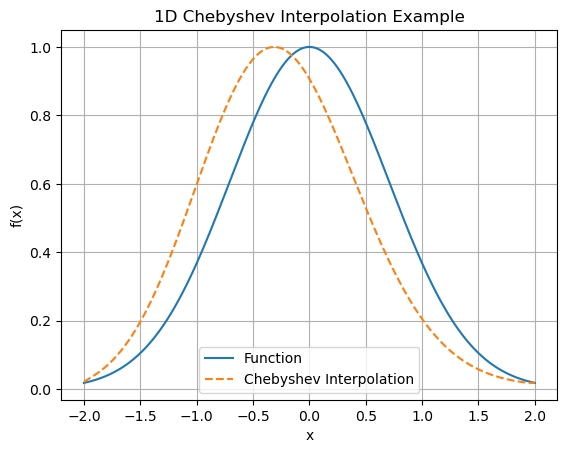

In [19]:
# Plotting the results
plt.plot(x_test, y_vals, label='Function')
plt.plot(x_test, y_interp, label='Chebyshev Interpolation', linestyle='--')
plt.legend()
plt.title('1D Chebyshev Interpolation Example')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.grid()
plt.show()

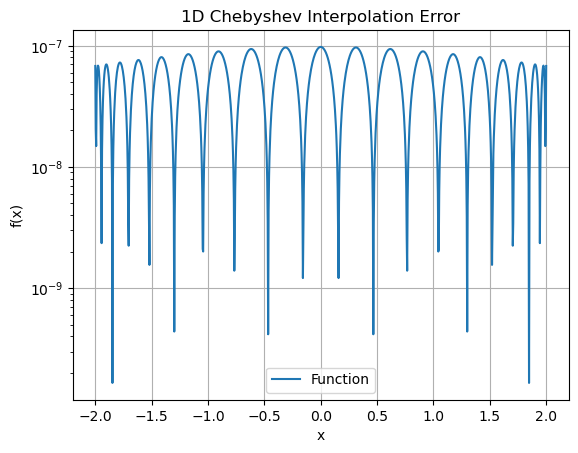

In [17]:
# Plotting the results
plt.plot(x_test, abs(y_vals - y_interp), label='Function')
plt.legend()
plt.title('1D Chebyshev Interpolation Error')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.yscale('log')
plt.grid()
plt.show()